## サイン波の予測

In [77]:
import torch
from torch import nn, optim
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset, random_split
import numpy as np
import matplotlib.pyplot as plt
import json
import h5py
import pickle
import os
import sys
import shutil
from tqdm import tqdm
from IPython.display import display, Image

__home__ = os.path.abspath("../../../../")
__module__ = os.path.join(__home__, "modules")
sys.path.append(__module__)
import Mytools.Settings # type: ignore
from Mytools.Tools import * # type: ignore

cachedir = os.path.join(__home__, "_cache")
os.makedirs(cachedir, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cuda


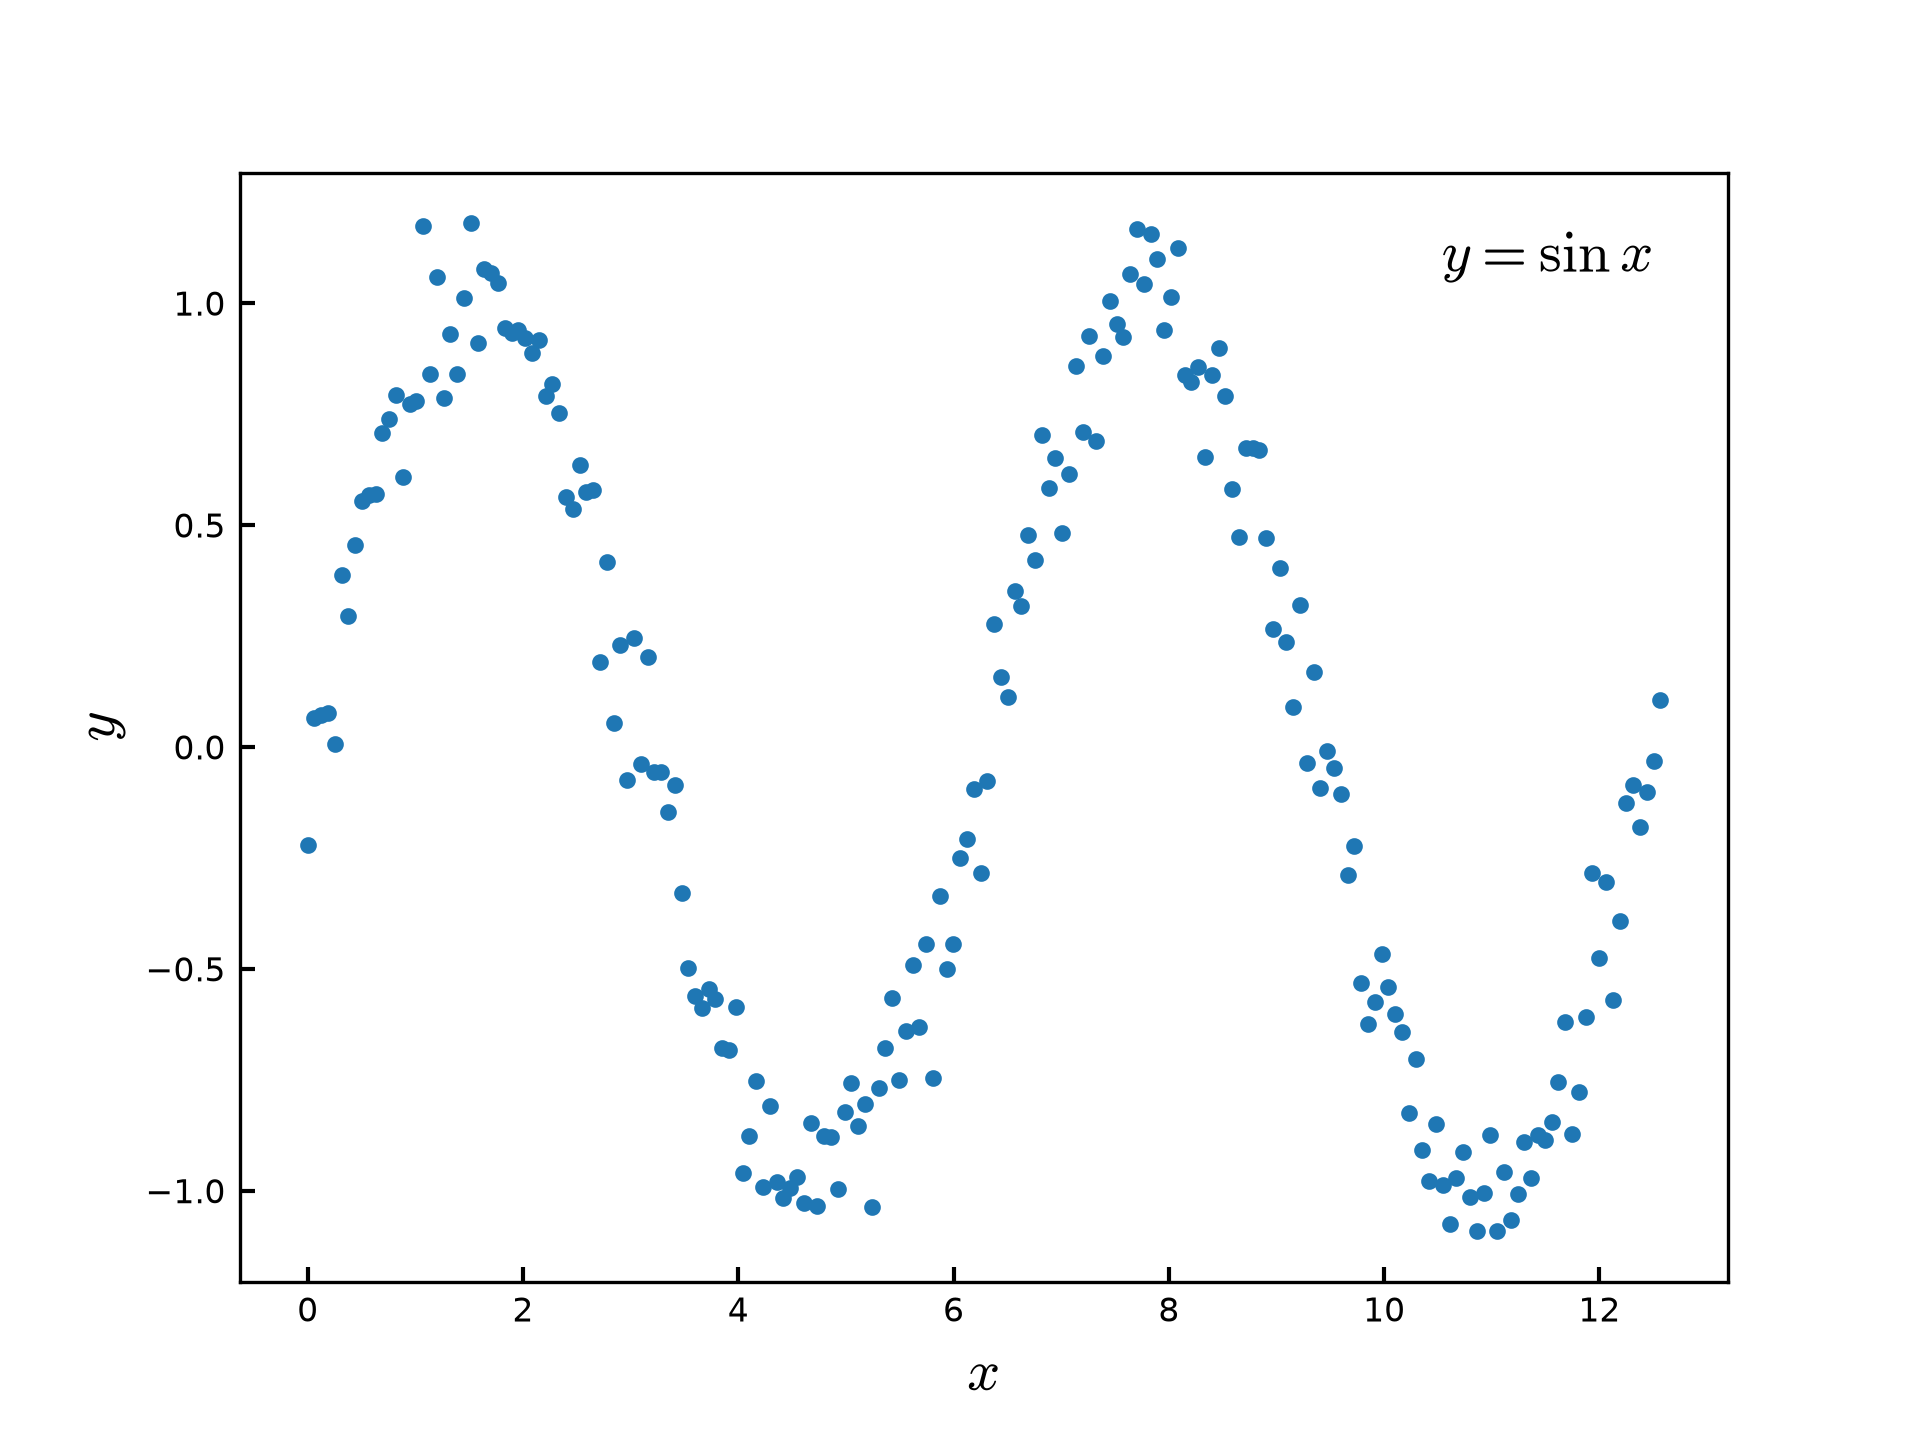

In [78]:
# 訓練データの生成
def generate_train_data():

    # 訓練データ
    x = np.linspace(0, 4*np.pi, 200)
    rng = np.random.default_rng(seed = 2025) # 乱数生成（シードは2025）
    sin_x = np.sin(x) + rng.normal(0, 0.1, len(x)) # ランダム誤差を導入

    # グラフ生成
    fig,ax = plt.subplots()
    ax.plot(x,sin_x,
            lw = 0,
            marker = ".",)
    pngpath = os.path.join(cachedir, "training.png")
    ax.set_xlabel(r"$x$", fontsize = 14)
    ax.set_ylabel(r"$y$", fontsize = 14)
    ax.text(
        x = 0.95,
        y = 0.95,
        s = r"$y=\sin{x}$",
        transform = ax.transAxes,
        ha = "right",
        va = "top",
        fontsize = 14
    )
    plt.savefig(pngpath, dpi = 300)
    plt.close()
    display(Image(pngpath, width = 600))

    return {"x": x, "y": sin_x}

TrainingData = generate_train_data()
del generate_train_data

In [79]:
# ハイパーパラメータ
hyper_parameter = {
    "n_time": 40,
    "batch_size": 32,
    "length": {
        "train": 0.8,
        "validation": 0.1
    }
}
print(json.dumps(hyper_parameter, indent = 4))

{
    "n_time": 40,
    "batch_size": 32,
    "length": {
        "train": 0.8,
        "validation": 0.1
    }
}


In [80]:
# 前処理
def process_data(data, parameter):

    ## サンプル数を計測
    n_sample = len(data["x"]) - parameter["n_time"]

    ## 空の配列を準備
    input_data = np.zeros((n_sample, parameter["n_time"], 1))
    correct_data = np.zeros((n_sample, 1))

    ## 配列にTrainDataを格納
    for i in tqdm(range(n_sample)):
        input_data[i] = data["y"][i:i+parameter["n_time"]].reshape(-1,1)
        correct_data[i] = [data["y"][i+parameter["n_time"]]]
    input_data = torch.FloatTensor(input_data)
    correct_data = torch.FloatTensor(correct_data)

    ## バッチデータの準備
    full_dataset = TensorDataset(input_data, correct_data)
    n_total = len(full_dataset)
    n_train = int(hyper_parameter["length"]["train"]*n_total)
    n_val = int(hyper_parameter["length"]["validation"]*n_total)
    n_test = n_total-n_train-n_val

    ## データを分類
    dataset = random_split(
        full_dataset,
        [n_train, n_val, n_test],
        generator = torch.Generator().manual_seed(42)
    )
    loader = {}
    for k, d in zip(["train", "val", "test"], dataset):
        loader[k] = DataLoader(
            d,
            batch_size = parameter["batch_size"],
            shuffle = True if (k=="train") else False
        )

    return dataset, loader
dataset, loader = process_data(data = TrainingData, parameter = hyper_parameter)

100%|██████████| 160/160 [00:00<00:00, 575547.72it/s]


In [81]:
# モデルの定義（初期化）

## クラスの定義
class RNN(nn.Module):
    def __init__(self): # コンストラクタを定義
        super(RNN, self).__init__()
        self.rnn = nn.RNN(1, 64, batch_first=True) # RNNのモジュール（入力1、隠れ層64）
        self.fc = nn.Linear(64, 1) # 全結合層（入力64、出力1）
    def forward(self, x):
        batch_size = x.size(0) # 入力の行数をバッチサイズに設定
        x = x.to(device) # 処理をGPUに移行
        x_rnn, hidden = self.rnn(x, None) # ?
        x = self.fc(x_rnn[:, -1, :])
        return x

## 初期化
model = RNN().to(device)
criterion = nn.MSELoss() # 平均二乗誤差
optimizer = optim.SGD(model.parameters(), lr=0.01) # 確率的勾配降下法

## 保存用の変数を定義
record_loss_train = []
record_loss_val = []
epoch = 0

## 保存用ディレクトリを定義
savedir_model = os.path.join(cachedir, "models")
if os.path.exists(savedir_model):
    shutil.rmtree(savedir_model)
os.makedirs(os.path.join(cachedir, "models"))

In [82]:
# 学習

## 学習するエポック数
add_epoch = 5000

for _ in tqdm(range(add_epoch)):
    epoch += 1
    
    ## 訓練を行う
    model.train() # 訓練モード
    loss_train = 0 # lossの平均を監視する
    for j, (x, t) in enumerate(loader["train"]):
        loss = criterion(model(x), t.to(device))
        loss_train += loss.item()
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    loss_train /= j+1
    record_loss_train.append(loss_train)

    model.eval()
    loss_val = 0
    with torch.no_grad():
        for j, (x, t) in enumerate(loader["val"]):
            loss = criterion(model(x), t.to(device))
            loss_val += loss.item()
        loss_val /= j+1
        record_loss_val.append(loss_val)

    filename = "model_epoch{}.pth".format(epoch)
    save_path = os.path.join(savedir_model, filename)
    torch.save(model.state_dict(), save_path)

print("Now {} epoch".format(epoch))

100%|██████████| 5000/5000 [00:37<00:00, 133.29it/s]

Now 5000 epoch


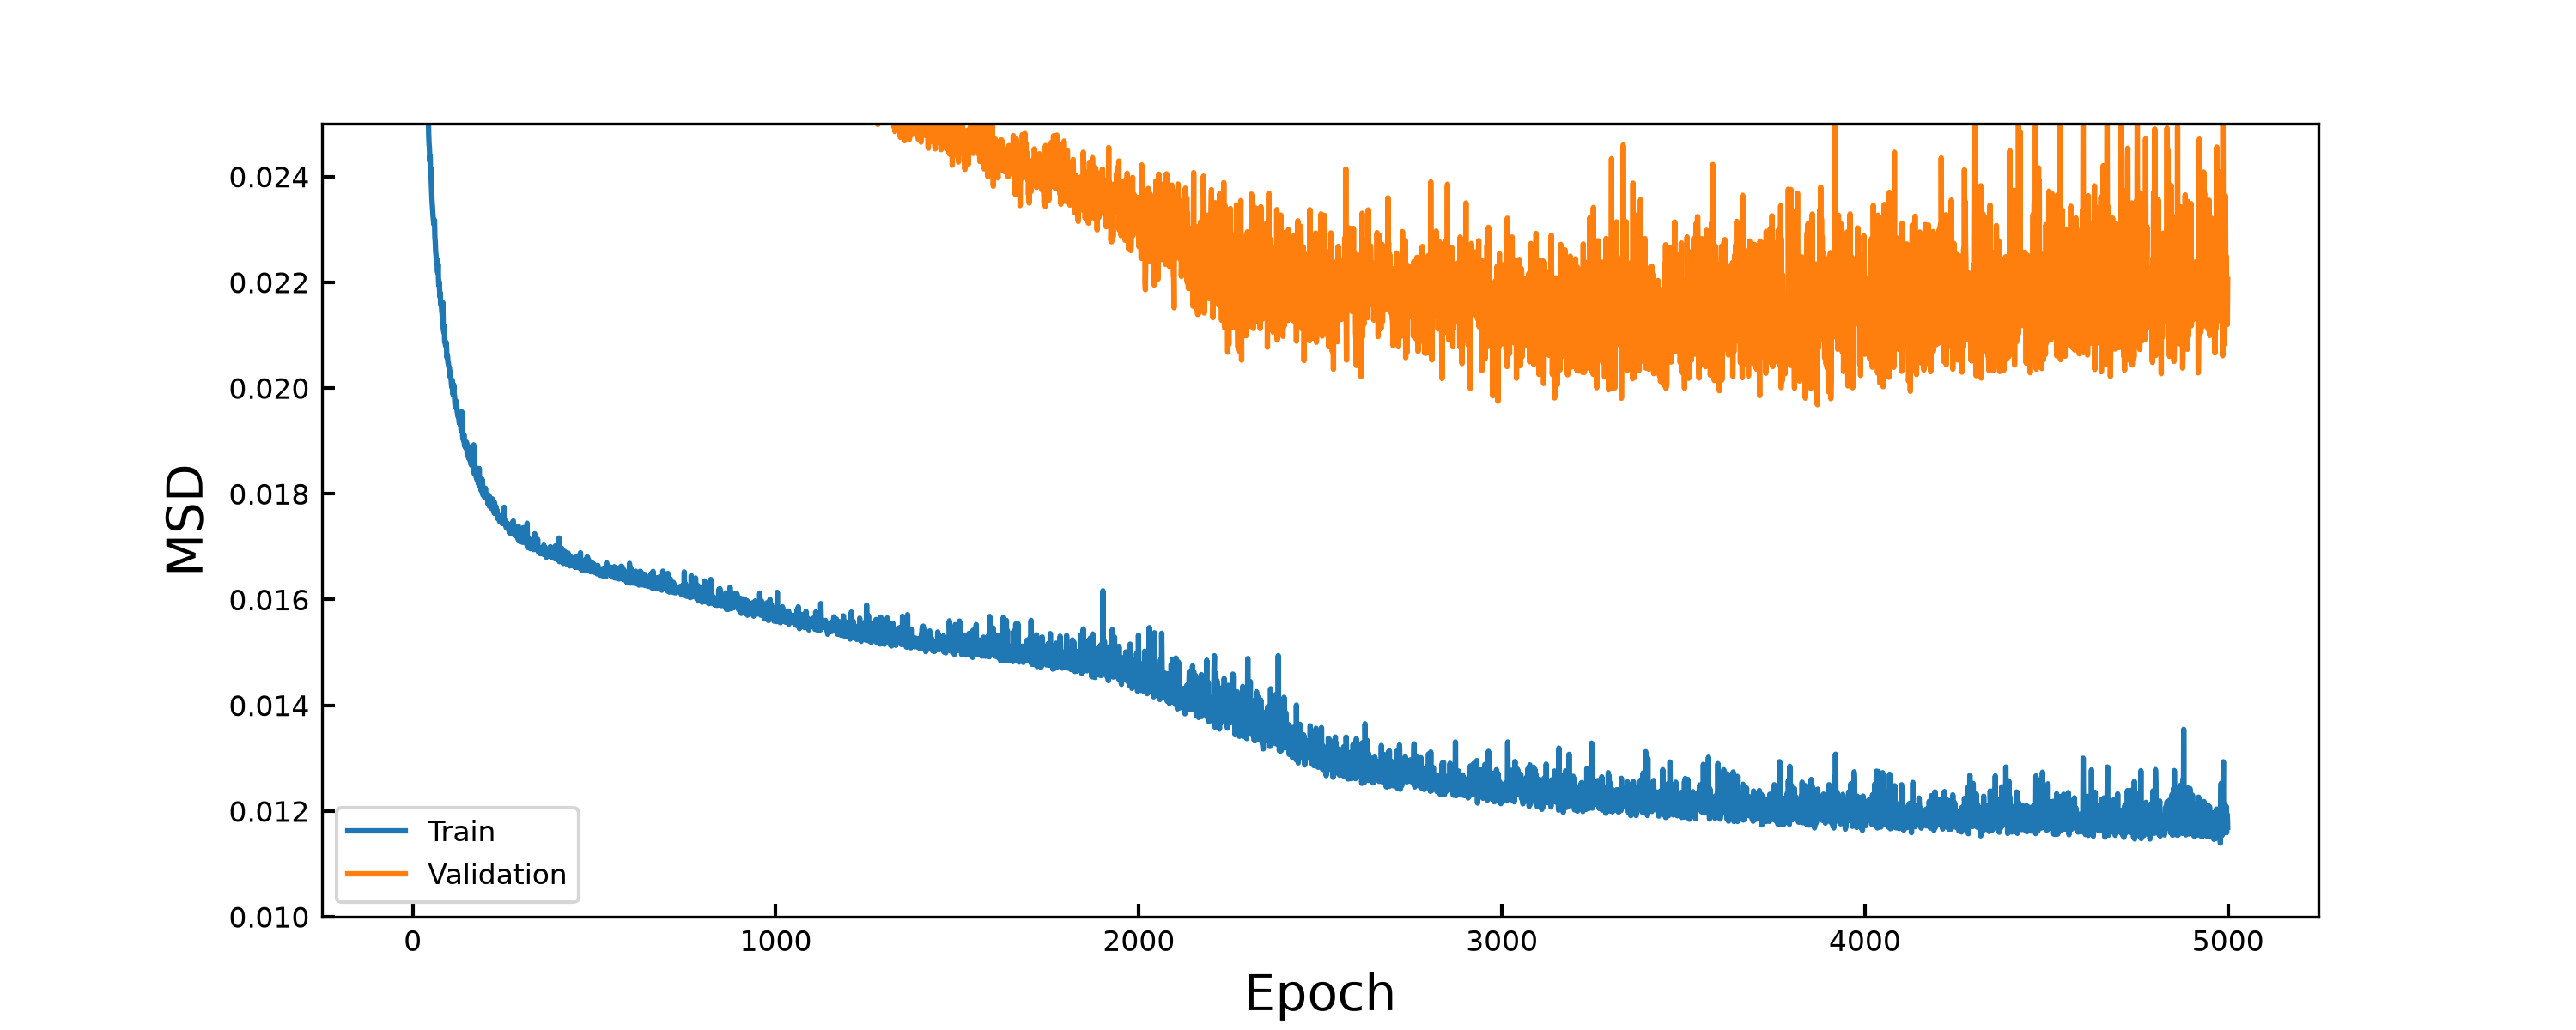

In [83]:
# 学習履歴の可視化
def display_historical_curve(len_epoch, loss_train, loss_val):
    fig, ax = plt.subplots()
    fig.set_size_inches(10,4)

    ax.plot(
        range(len_epoch), # type: ignore
        loss_train, 
        label = "Train"
    )
    ax.plot(
        range(len_epoch), # type: ignore
        loss_val,
        label = "Validation"
    )
    ax.set_ylim(0,0.1)
    ax.set_ylim(0,0.04)
    ax.set_ylim(0.01,0.025)
    # ax.set_xlim(0,1000)
    ax.legend()
    ax.set_xlabel("Epoch", fontsize = 14)
    ax.set_ylabel("MSD", fontsize = 14)
    pngpath = os.path.join(cachedir, "train_history.png")
    plt.savefig(pngpath, dpi = 300)
    plt.close()
    display(Image(pngpath, width = 600))
    
display_historical_curve(
    epoch, # type: ignore
    record_loss_train,
    record_loss_val
)
del display_historical_curve

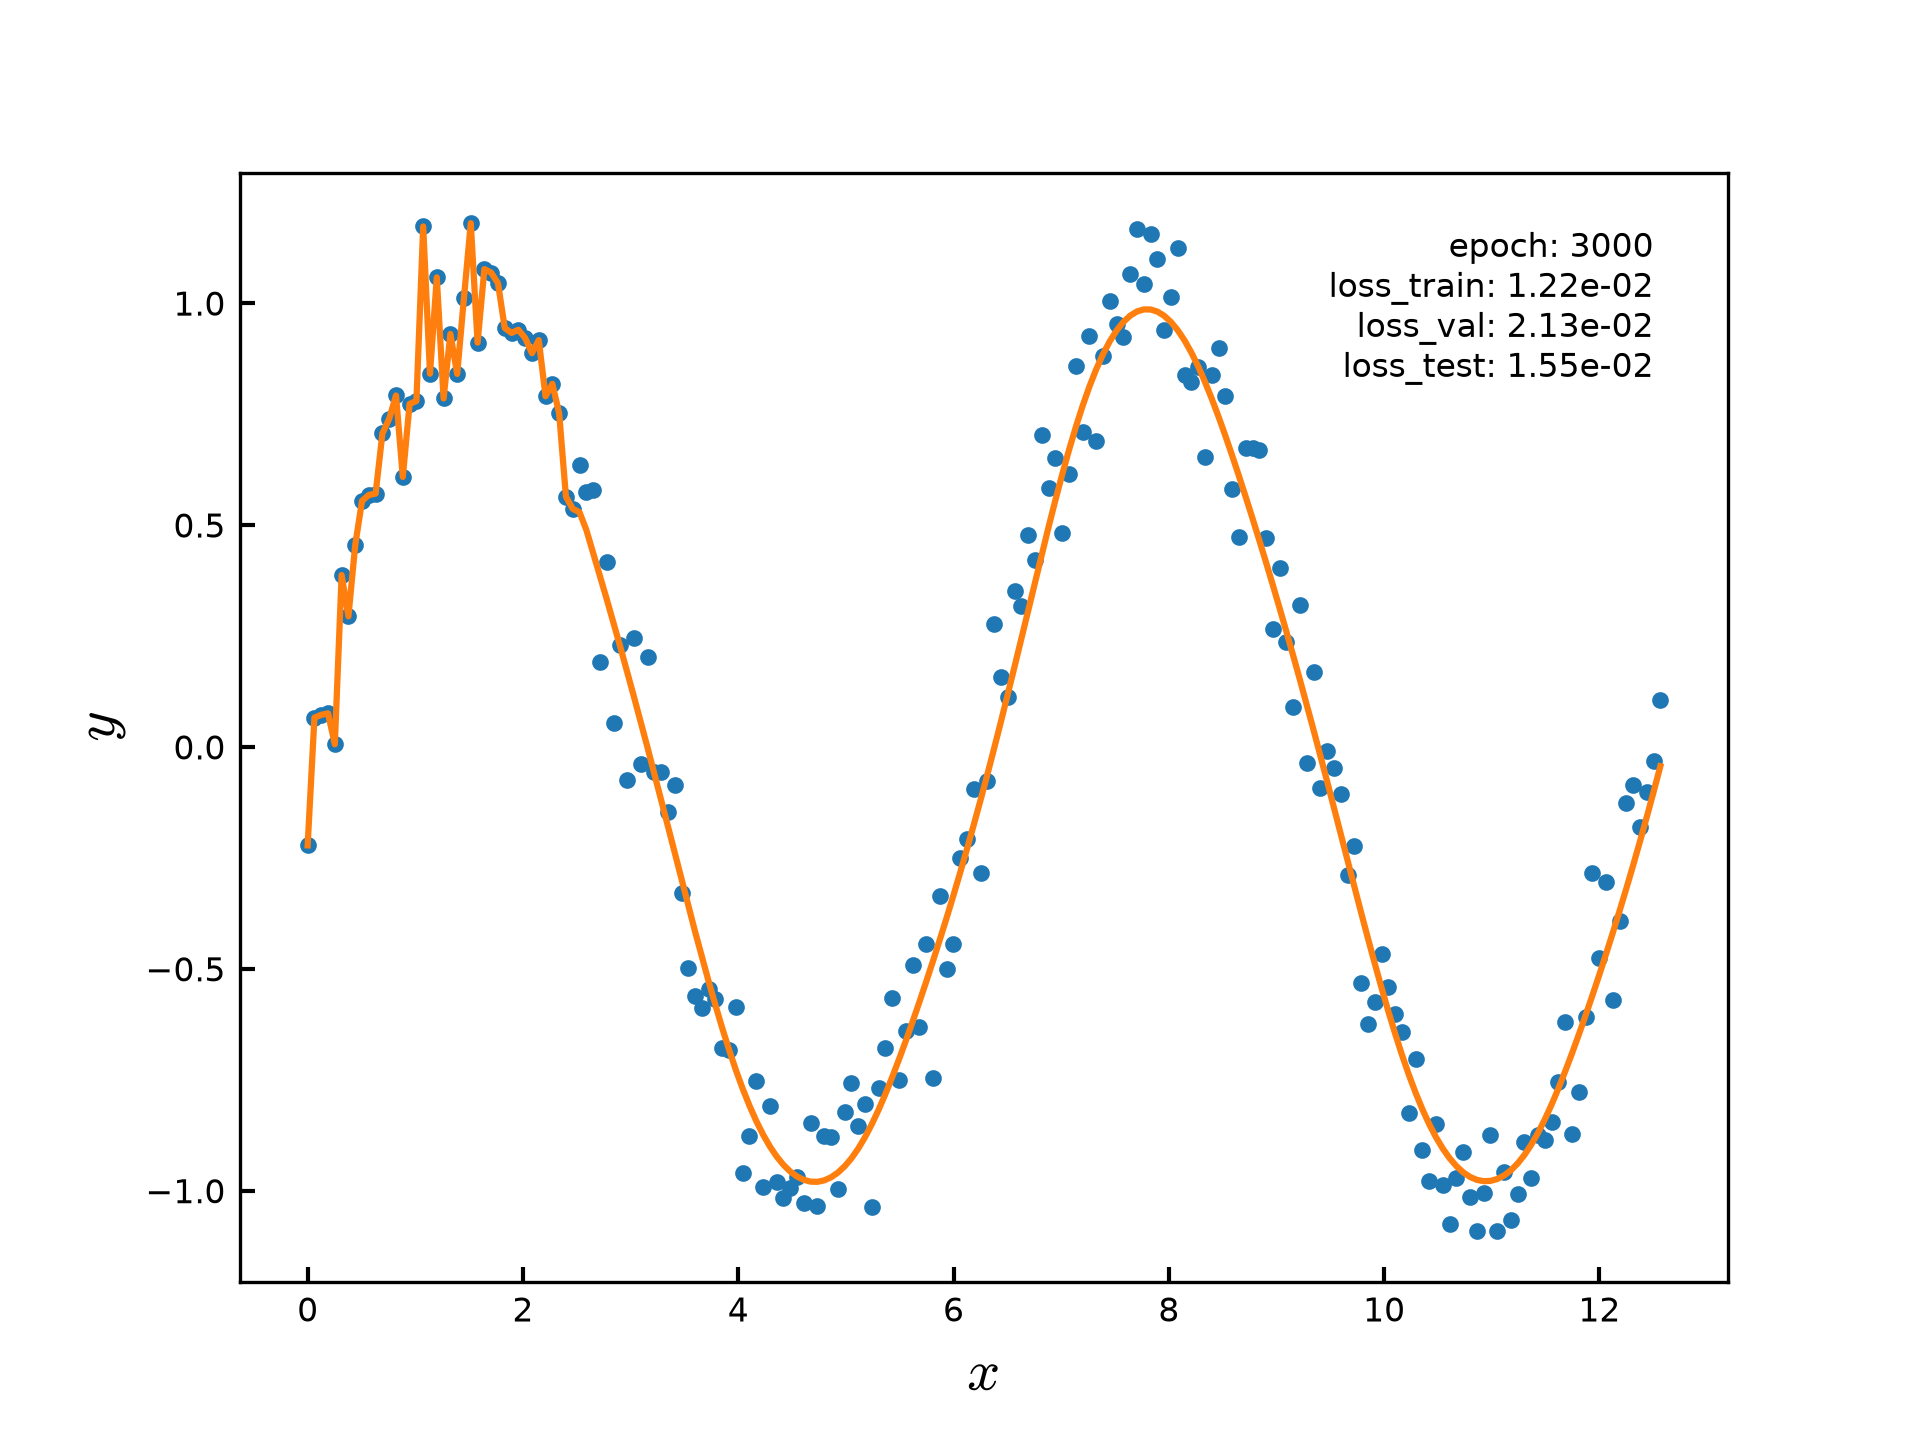

In [85]:
display_epoch = 3000 # 閲覧するモデルのエポック

def display_TrainResult(ep, directory, rawdata, parameter, loss_train, loss_val):
    
    ## データの読み込み
    model_path = os.path.join(directory,"models", "model_epoch{}.pth".format(ep))
    historical_model = RNN().to(device)
    historical_model.load_state_dict(torch.load(model_path))

    historical_model.eval() # 評価モードに切り替え
    predicted = list(rawdata["y"][:parameter["n_time"]])
    with torch.no_grad(): # 勾配計算の停止
        for i in range(len(rawdata["x"]) - parameter["n_time"]):
            x = torch.tensor(
                predicted[-parameter["n_time"]:],
                dtype = torch.float32
            ).reshape(1,-1,1).to(device)
            predicted.append(historical_model(x)[0].item())

        loss_test = 0
        for j, (x, t) in enumerate(loader["test"]):
            loss = criterion(historical_model(x), t.to(device))
            loss_test += loss.item()
        loss_test /= j+1

    fig, ax = plt.subplots()
    ax.plot(
        TrainingData["x"],
        TrainingData["y"],
        lw = 0,
        marker = ".",
        label = "Correct"
    )
    ax.plot(
        TrainingData["x"],
        predicted,
        label = "Model"
    )
    ax.set_xlabel(r"$x$", fontsize = 14)
    ax.set_ylabel(r"$y$", fontsize = 14)
    text = "epoch: {}\n".format(ep)
    text  += "loss_train: {:.2e}\n".format(loss_train[ep])
    text += "loss_val: {:.2e}\n".format(loss_val[ep])
    text += "loss_test: {:.2e}".format(loss_test)
    ax.text(
        x = 0.95,
        y = 0.95,
        s = text,
        transform = ax.transAxes,
        ha = "right",
        va = "top"
    )
    pngpath = os.path.join(cachedir, "result.png")
    plt.savefig(pngpath, dpi = 300)
    plt.close()
    display(Image(pngpath, width = 600))

display_TrainResult(
    ep = display_epoch,
    directory = cachedir,
    rawdata = TrainingData,
    parameter = hyper_parameter,
    loss_train = record_loss_train,
    loss_val = record_loss_val
)
del display_TrainResult